#Phase 4: Statistical evidence

In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

In [5]:
df = pd.read_csv(r"C:\Users\Gafoo\OneDrive\Documents\GitHub\Olist-Customer-Experience-Analytics\notebooks\data\clean_orders.csv",
                 parse_dates=["order_purchase_timestamp"])

df.shape

(95560, 55)

In [ ]:
df["delay_bucket"] = pd.cut(df.days_late, bins=[-np.inf, 0, 3, 7, np.inf],
                            labels=["On time", "1-3 late", "4-7 late", "8+ late"])
late, ontime = df[df.is_late == 1], df[df.is_late == 0]


**Test 1: Are late orders more likely to get bad reviews?**

In [30]:
p_late = late.low_review.mean()
p_ontime = ontime.low_review.mean()

print(f"Low-review rate, late orders:    {p_late:.1%}")
print(f"Low-review rate, on-time orders: {p_ontime:.1%}")
print(f"Difference: {(p_late - p_ontime)*100:.1f} percentage points")
print(f"Late orders are {p_late / p_ontime:.1f}x as likely to get a 1-2 star review")

Low-review rate, late orders:    62.4%
Low-review rate, on-time orders: 9.2%
Difference: 53.2 percentage points
Late orders are 6.7x as likely to get a 1-2 star review


## Test 1: Are late orders more likely to get bad reviews?

| Group | Orders | Bad-review rate |
|---|---|---|
| On time | about 89,200 | **9.2%** |
| Late | about 6,400 | **62.4%** |

**Result:** The gap is **53.2 percentage points**. Late orders are **6.7x** as likely to get a 1-2 star review.

**In plain English:** Out of 100 on-time orders, about 9 get a bad review. Out of 100 late orders, about 62 do.

**Why it matters:** This is the strongest number for the logistics negotiation.

“Among late orders, 62.4% received a 1-2 star review, compared with 9.2% for on-time orders. That’s a 53-point gap, and late orders are 6.7 times as likely to be rated poorly. These are the headline numbers, and the confidence intervals from the earlier analysis show they’re precise.”

**Test 2: Is the gap real, or just luck? (Chi-square test)**

In [32]:
table = pd.crosstab(df.is_late, df.low_review)
chi2, p_value, _, _ = stats.chi2_contingency(table)
print("p-value:", p_value)

p-value: 0.0


## Test 2: Is the gap real or just luck? (Chi-square test)

**Question:** If lateness had no effect on reviews, how likely is it that we would see a gap this big by chance?

**Result:** p-value is below 0.0001 (Python prints 0.0 because it rounds, it is not exactly zero).

**In plain English:** The chance of this being luck is practically zero. The standard cutoff is 0.05, and we are far below it.

**Caution:** With about 95,000 orders, almost any gap looks "significant". So a small p-value alone is not impressive. What matters is the **size** of the gap (53 points), which is huge.

**Test 3: How sure are you about the size? (Bootstrap confidence interval)**

In [33]:
rng = np.random.default_rng(42)
diffs = []
for _ in range(2000):
    a = rng.choice(late.low_review.values, len(late)).mean()
    b = rng.choice(ontime.low_review.values, len(ontime)).mean()
    diffs.append(a - b)

low, high = np.percentile(diffs, [2.5, 97.5]) * 100
print(f"95% confidence interval for the gap: {low:.1f} to {high:.1f} percentage points")

95% confidence interval for the gap: 51.9 to 54.4 percentage points


## Test 3: How sure are we about the size? (Bootstrap confidence interval)

**Method:** I re-drew random samples from the data 2,000 times and recalculated the gap each time.

**Result:** 95% of the results fell between **51.9 and 54.4 percentage points**.

**In plain English:** Our best estimate is a 53-point gap. Even in the pessimistic case it is still about 52 points. The range is narrow, so we are confident about the size, not just the direction.

**Test 4: Does it get worse the later the order is? (Dose-response)**

In [34]:
df["delay_bucket"] = pd.cut(df.days_late, [-np.inf, 0, 3, 7, np.inf],
                            labels=["On time", "1-3 days late", "4-7 days late", "8+ days late"])
print(df.groupby("delay_bucket", observed=True).agg(
        orders=("order_id", "count"),
        avg_score=("review_score", "mean"),
        low_review_pct=("low_review", "mean")).round(3))

               orders  avg_score  low_review_pct
delay_bucket                                    
On time         89182      4.291           0.092
1-3 days late    1851      3.291           0.321
4-7 days late    1748      2.103           0.677
8+ days late     2779      1.697           0.793


## Test 4: Does it get worse the later the order is?

| Delay | Orders | Avg score | Bad-review rate |
|---|---|---|---|
| On time | 89,182 | 4.29 | 9.2% |
| 1-3 days late | 1,851 | 3.29 | 32.1% |
| 4-7 days late | 1,748 | 2.10 | 67.7% |
| 8+ days late | 2,779 | 1.70 | 79.3% |

**Result:** The score drops at every step. Even **1-3 days late** costs a full star, and 8+ days late almost wipes out the rating.

**In plain English:** The longer the delay, the worse the review. A smooth, step-by-step pattern is harder to explain away than a single late vs on-time comparison, which makes it more believable that delay itself matters.

**Business takeaway:** Customers react badly to even small delays, so the estimated delivery date is a promise they take seriously.

**Test 5: Does delivery still matter after considering other factors? (Logistic regression, simple version)**

In [35]:
d = df.dropna(subset=["distance_km", "freight_ratio"]).copy()
d["distance_100km"] = d.distance_km / 100

model = smf.logit("low_review ~ is_late + items_price + freight_ratio + distance_100km + estimated_days",
                  data=d).fit(disp=0)

odds = np.exp(model.params).round(2)
print(odds)
print(model.pvalues.round(4))

Intercept          0.05
is_late           17.29
items_price        1.00
freight_ratio      1.20
distance_100km     0.99
estimated_days     1.02
dtype: float64
Intercept         0.0
is_late           0.0
items_price       0.0
freight_ratio     0.0
distance_100km    0.0
estimated_days    0.0
dtype: float64


## Test 5: Does lateness still matter after considering other factors?

**The skeptic's question:** "Maybe late orders are the expensive or far-away ones, and customers are upset about price or distance, not lateness."

**Method:** Logistic regression predicts a yes/no outcome (bad review) from several factors at once. It shows the effect of one factor while holding the others equal.

| Factor | Odds ratio | Meaning |
|---|---|---|
| **is_late** | **17.3** | Strong. Late orders have about 17x the odds of a bad review, after holding the others equal |
| freight_ratio | 1.20 | Small. Higher shipping cost relative to price raises the odds a little |
| estimated_days | 1.02 | Tiny. Each extra promised day adds about 2% to the odds |
| items_price | 1.00 | No effect |
| distance_100km | 0.99 | No effect. Distance itself does not hurt reviews |

**How to read an odds ratio:** 1 means no effect, above 1 means more bad reviews, below 1 means fewer.

**Result:** Lateness is by far the strongest factor. It is not standing in for price or distance.

**Note:** The odds ratio (17) is bigger than the 6.7x from Test 1 because odds and probability are different things. Use "6.7x as likely" when speaking to business people, and use the odds ratio only when describing the model.

**Limitation:** Orders from the same seller are not fully independent, so the confidence ranges may be slightly too narrow. With more time I would adjust for this.

**Test 6: Is delivery the whole story?**

In [36]:
total_low = df.low_review.sum()
excess = (p_late - p_ontime) * len(late)
print(f"About {excess/total_low:.0%} of all bad reviews are linked to late delivery")
print(f"Share of bad reviews that came from on-time orders: {(1 - df[df.low_review==1].is_late.mean()):.0%}")

About 28% of all bad reviews are linked to late delivery
Share of bad reviews that came from on-time orders: 67%


## Test 6: Is delivery the whole story?

**Question:** If we fixed every late delivery, would the bad reviews go away?

**Result**
- **33%** of all bad reviews come from late orders
- **67%** of bad reviews come from orders that arrived on time
- If late orders performed like on-time ones, bad reviews would fall by about **28%**

**Why 33% and 28% are different:** 33% counts every bad review on a late order. But even on-time orders get bad reviews 9% of the time, so some late orders would have been unhappy anyway. 28% is the part that lateness adds on top of that baseline.

**In plain English:** Late delivery is the strongest single driver, but late orders are only about 7% of orders. Two-thirds of bad reviews come from somewhere else, so ops is partly right, and product quality and seller issues also matter.

**Next step:** Review-text analysis (GenAI) will show what the other two-thirds are about.

## Conclusion

1. **Late orders get bad reviews 6.7x as often** (62% vs 9%), a gap of 53 points (95% CI: 52 to 54).
2. **It gets worse with delay.** Even 1-3 days late drops the average score by a full star.
3. **It holds after controlling for price, freight, and distance.** Lateness is the strongest factor.
4. **But it is not the whole story.** About two-thirds of bad reviews come from on-time orders.

**Limits**
- Observational data: I can show a strong, consistent link but cannot prove delay *causes* the bad review.
- Only delivered orders with a review are included (customers who did not review are missing).
- Orders from the same seller are not fully independent.

**Recommendation for next phases:** Build an early-warning model for risky orders, and use the review text to understand the non-delivery complaints.

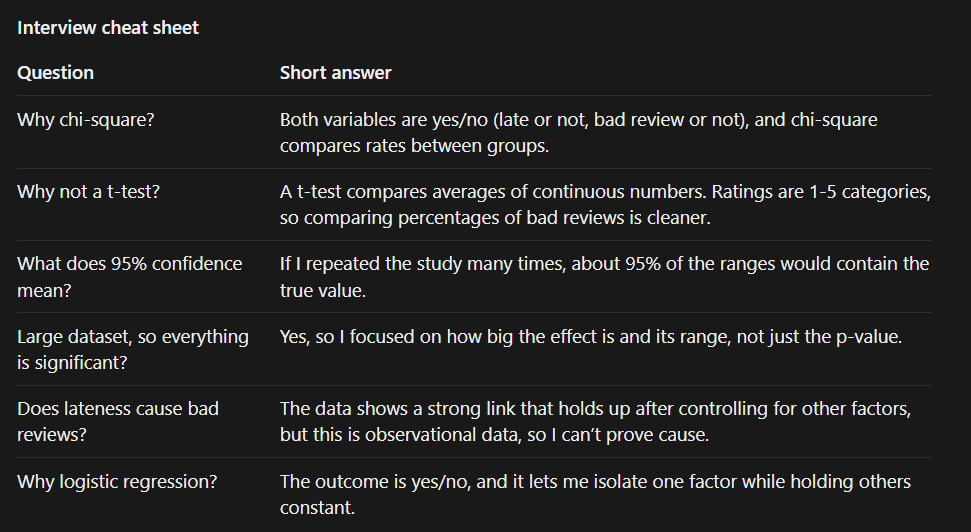